In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit.Chem import Draw
from rdkit import Chem

In [3]:
data_path="../data/zinc.csv"
df=pd.read_csv(data_path,on_bad_lines="skip")
df.describe()


,logP,qed,SAS
count,249455.000000,249455.000000,249455.000000
mean,2.457093,0.728264,3.053235
std,1.434330,0.139565,0.834796
min,-6.876200,0.111811,1.132738
25%,1.574810,0.645872,2.416627
50%,2.605600,0.759878,2.892993
75%,3.486760,0.835714,3.545533
max,8.252100,0.947882,7.289283


In [4]:
df.head()

,smiles,logP,qed,SAS
0,CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1\r\n,5.05060,0.702012,2.084095
1,C[C@@H]1CC(Nc2cncc(-c3nncn3C)c2)C[C@@H](C)C1\r\n,3.11370,0.928975,3.432004
2,N#Cc1ccc(-c2ccc(O[C@@H](C(=O)N3CCCC3)c3ccccc3)...,4.96778,0.599682,2.470633
3,CCOC(=O)[C@@H]1CCCN(C(=O)c2nc(-c3ccc(C)cc3)n3c...,4.00022,0.690944,2.822753
4,N#CC1=C(SCC(=O)Nc2cccc(Cl)c2)N=C([O-])[C@H](C#...,3.60956,0.789027,4.035182


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249455 entries, 0 to 249454
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   smiles  249455 non-null  object 
 1   logP    249455 non-null  float64
 2   qed     249455 non-null  float64
 3   SAS     249455 non-null  float64
dtypes: float64(3), object(1)
memory usage: 7.6+ MB


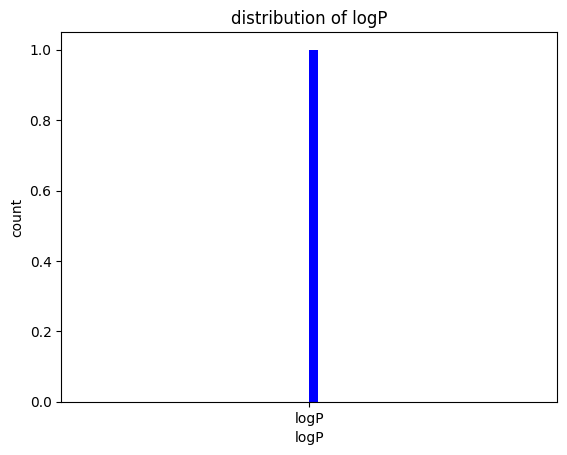

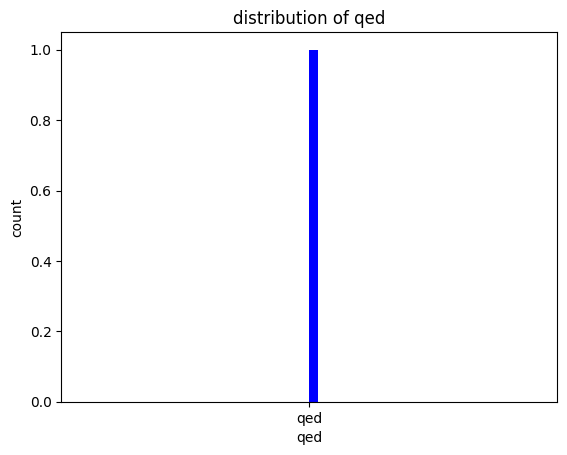

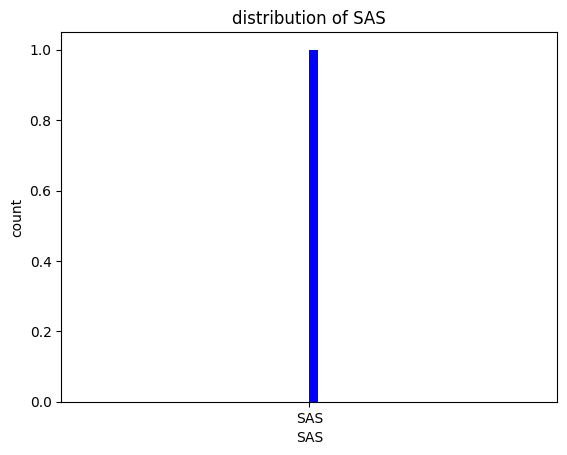

In [6]:
features=df.drop(columns=["smiles"])
for i in features.columns:
    plt.figure()
    plt.hist(i,bins=50,color="blue")
    plt.title(f"distribution of {i}")
    plt.xlabel(i)
    plt.ylabel("count")
    plt.show()

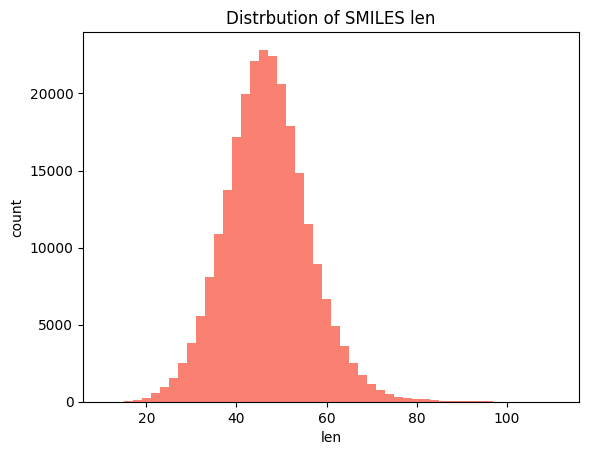

In [7]:
df['smiles_len']=df["smiles"].apply(len)
plt.hist(df["smiles_len"],bins=50,color="salmon")
plt.title('Distrbution of SMILES len')
plt.xlabel('len')
plt.ylabel('count')
plt.show()



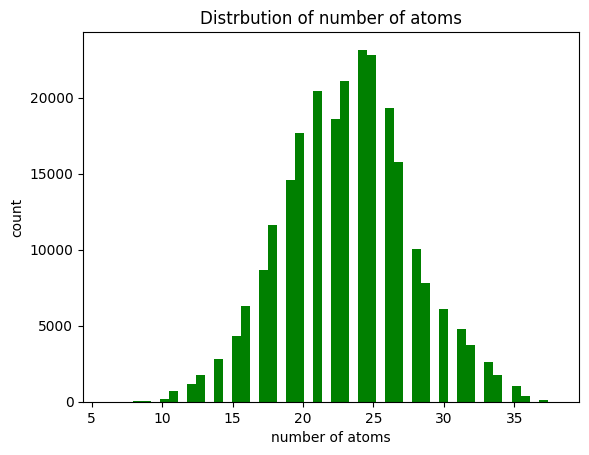

In [8]:
df['mol']=df["smiles"].apply(lambda x:Chem.MolFromSmiles(x))
df=df[df["mol"].notnull()]
df["num_atom"]=df['mol'].apply(lambda m: m.GetNumAtoms())
plt.hist(df["num_atom"],bins=50,color="green")
plt.title('Distrbution of number of atoms')
plt.xlabel('number of atoms')
plt.ylabel('count')
plt.show()


In [9]:
df.describe()

,logP,qed,SAS,smiles_len,num_atom
count,249455.000000,249455.000000,249455.000000,249455.000000,249455.000000
mean,2.457093,0.728264,3.053235,46.310461,23.151362
std,1.434330,0.139565,0.834796,9.326142,4.509344
min,-6.876200,0.111811,1.132738,11.000000,6.000000
25%,1.574810,0.645872,2.416627,40.000000,20.000000
50%,2.605600,0.759878,2.892993,46.000000,23.000000
75%,3.486760,0.835714,3.545533,52.000000,26.000000
max,8.252100,0.947882,7.289283,111.000000,38.000000


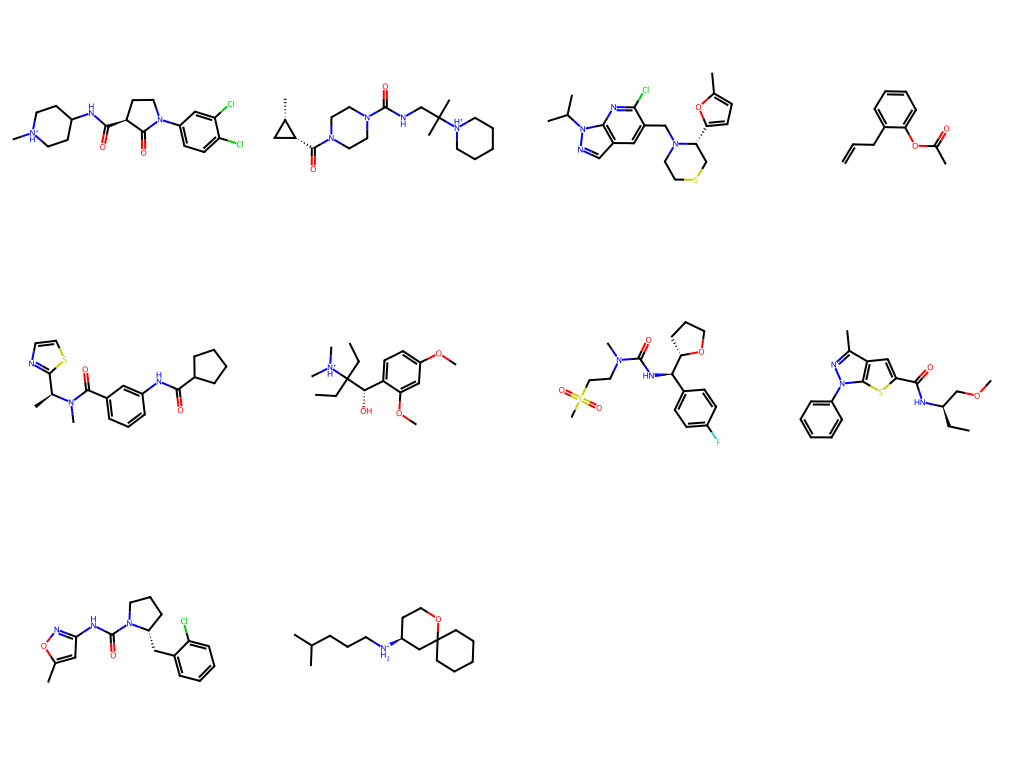

In [ ]:
s_mols=df["mol"].sample(10,random_state=42).tolist()
img=Draw.MolsToGridImage(s_mols,molsPerRow=4,subImgSize=(256,256))
img

In [10]:
from collections import Counter
atom_counter=Counter()
total_atom=0
for i in df["smiles"]:
    mol=Chem.MolFromSmiles(i)
    if mol is None:
        continue
    for atom in mol.GetAtoms():
        symbol=atom.GetSymbol()
        atom_counter[symbol]+=1
        total_atom+=1
probs={k: v/total_atom for k,v in atom_counter.items()}
print(atom_counter)
print(probs)

Counter({'C': 4254871, 'N': 705203, 'O': 576231, 'S': 102879, 'F': 79430, 'Cl': 42872, 'Br': 12722, 'I': 888, 'P': 127})
{'C': 0.736745749904376, 'O': 0.09977640690238282, 'N': 0.12210835841317297, 'F': 0.0137535814634344, 'S': 0.017813857577447658, 'Cl': 0.007423436289819458, 'Br': 0.002202858660176412, 'I': 0.00015376029635565588, 'P': 2.1990492834648984e-05}


In [13]:
bond_counter=Counter()
total_bond=0
for i in df["smiles"]:
    mol=Chem.MolFromSmiles(i)
    if mol is None:
        continue
    for bond in mol.GetBonds():
        bond_type=str(bond.GetBondType())
        bond_counter[bond_type]+=1
        total_bond+=1
probs={k: v/total_bond for k,v in bond_counter.items()}
print(bond_counter)
print(probs)

Counter({'SINGLE': 3208641, 'AROMATIC': 2592063, 'DOUBLE': 395693, 'TRIPLE': 15587})
{'SINGLE': 0.51652435035248, 'AROMATIC': 0.4172681384884443, 'DOUBLE': 0.06369832890747948, 'TRIPLE': 0.0025091822515962694}
